# PLC Sequence Control: Scan Cycle, Timers, Counters and a Batching Station

`07_plc_sequence` | level 2 | experiment id(s): `exp_07_plc_batching_station`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 2 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Explain the PLC scan cycle (read inputs, execute, write outputs) and what it implies for timers,
  edge detection and short input pulses.
- Verify standard function blocks (TON, TOF, CTU, R_TRIG, SR latch) against timing diagrams derived
  by hand, counted in scans.
- Build a batching-station program (start/stop seal-in, bottle counter, settle timer, packer timer)
  and check its outputs scan by scan against an expected timeline.
- Quantify how scan time limits timer accuracy and the probability of missing a short sensor pulse.

## 2. Real-World Engineering Problem

A conveyor counts six bottles, stops, waits for them to settle, runs a packer for a fixed time, and
restarts. The stop button must stop the machine even if its wire breaks, and a start/stop press at
the same time must not run the machine. A sensor pulse shorter than the scan time can be missed
entirely, and a timer cannot be more accurate than the scan time. These are the properties checked here.

## 3. Research Background

IEC 61131-3 defines the standard function blocks and the programming languages used on PLCs.
The scan model used here is the common cyclic one (latched input image, one program execution,
output image written at the end). Sequence logic of this kind is a finite state machine in
disguise (notebook 05; Moore, 1956).

## 4. Research Literature

The standard edition verified here (2013) is not the latest; the full text is paid and was not read.
The function-block behaviour implemented here is the commonly documented one (rising edge, timer
elapsed time, counter on rising edge), checked against hand-derived timing, not against the
standard text.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| moore1956 | Moore, E. F. (1956). Gedanken-experiments on sequential machines. Automata Studies (Annals of Mathematics Studies 34), ed. C. E. Shannon and J. McCarthy, Princeton University Press, 129-153. | Defines the machine whose output depends on the state only (Moore machine). | Theory of state identification experiments, not a control implementation guide. | verified (2026-11-25, web search of publisher/index/library record). Bibliographic record and a facsimile of the chapter agree on title, editors, series and pages. |
| iec61131_3 | IEC IEC 61131-3:2013, Programmable controllers - Part 3: Programming languages (edition 3.0, 2013-02-20) | Defines function blocks TON, TOF, CTU, R_TRIG, F_TRIG, SR and the scan execution model the PLC emulation follows. | The IEC webstore lists a more recent edition, IEC 61131-3:2025. The 2013 edition is the one verified here and may be withdrawn. | verified (2026-11-25, web search of publisher/index/library record). IEC webstore record; the full text was not read (paid standard). |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

**Scan model.** With scan time $\Delta$, scan $k$ latches inputs sampled at time $k\Delta$, executes
the program once, and the outputs become visible at the end of the scan, $(k+1)\Delta$.

**TON** (on-delay, preset $P$): elapsed time $e_k=\min(e_{k-1}+\Delta,P)$ while IN is true, else 0;
$Q$ is true when $e_k\ge P$. If IN rises in scan $k_0$, $Q$ first becomes true in scan
$k_0+\lceil P/\Delta\rceil-1$, i.e. a delay of $\lceil P/\Delta\rceil\Delta$ (rounded **up** to a
multiple of the scan time). **TOF** is the mirror image after IN falls.

**Missed pulses.** An input pulse of width $w$ with a random phase relative to the scan clock is
seen by $\lceil\cdot\rceil$ scans with probability $\min(1,w/\Delta)$ of being seen at all (for
$w<\Delta$ the probability is $w/\Delta$). For $n$ independent pulses, all are counted with
probability $\min(1,w/\Delta)^n$.

**Counter.** CTU increments on rising edges of CU only; a high level held across scans counts once.

## 6. System Modeling

Batching station: sensor pulses (bottles) at 1 s spacing, count preset 6, settle time 1.0 s, packer
time 2.0 s. Inputs: `start_pb` (normally open), `stop_nc` and `estop_nc` (normally closed: **false**
means pressed or wire broken), `sensor`. Outputs: `run` (latch), `conveyor`, `batch_full`,
`packer`, `count`. Reference scan time 10 ms. All values illustrative.

## 7. Dataset and Measurement Data

No dataset. Sensor pulses are scripted (scenarios) or random (Monte Carlo for missed pulses, seed 20261125).

## 8. Algorithm Architecture

Program order inside one scan: edge detect start; combine stop and e-stop (NC contacts); reset-dominant
run latch; counter (reset from the **previous** scan's pack-done); settle timer on `batch_full`; packer
on when settled and e-stop healthy; pack timer on `packer`; conveyor = run and not batch_full. The order matters:
outputs depend on which block is evaluated first, which is why expected timelines below are derived in scan indices.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers.plc import CTU, TOF, TON, F_TRIG, R_TRIG, Program, SRLatch, run_scans
from control_lab.experiments import ExperimentRecord, check, save_figure
import pandas as pd

EXP = "exp_07_plc_batching_station"
SEED = 20261125
DT = 0.01

class BatchStation(Program):
    def __init__(self, pv=6, settle=1.0, pack=2.0):
        self.start_edge, self.latch = R_TRIG(), SRLatch(reset_dominant=True)
        self.ctr, self.settle, self.pack = CTU(pv), TON(settle), TON(pack)
        self.reset_next = False
    def scan(self, i, dt):
        start = self.start_edge.update(i["start_pb"])
        stop = (not i["stop_nc"]) or (not i["estop_nc"])
        run = self.latch.update(start, stop)
        full = self.ctr.update(i["sensor"], reset=self.reset_next)
        settled = self.settle.update(full, dt)
        packer = settled and i["estop_nc"]
        done = self.pack.update(packer, dt)
        self.reset_next = done
        return {"run": run, "conveyor": run and not full, "batch_full": full, "packer": packer, "count": self.ctr.cv}

def inputs_from(ranges, default=None):
    # ranges: {name: [(k0, k1), ...]} scan-index half-open intervals where the input differs from default
    base = {"start_pb": False, "stop_nc": True, "estop_nc": True, "sensor": False}
    def fn(t):
        k = int(round(t / DT)); d = dict(base)
        for name, rs in ranges.items():
            for k0, k1 in rs:
                if k0 <= k < k1:
                    d[name] = not base[name]
        return d
    return fn

def true_scans(rec, key):
    return [k for k, r in enumerate(rec) if r["out"][key]]

Inputs are defined by scan-index intervals so that expected outputs can be written as scan indices
without floating-point ambiguity.

## 10. Simulation and Numerical Analysis

Four groups of runs: function-block timing, batching scenarios, short-pulse Monte Carlo, and timer
resolution versus scan time.

## 11. Experimental Validation

Level: **software simulation**. The independent reference is hand-derived scan arithmetic (section 5).
No PLC, no IEC 61131-3 compliance test and no hardware were involved; this is an emulation of the
scan model, not a PLC runtime.

## 12. Performance Evaluation

In [3]:
checks = []

# A. function blocks against hand-derived timing (scan indices)
def drive(block, ins, dt=0.1, n=50):
    return [bool(block.update(i, dt)) if not isinstance(block, (CTU, SRLatch)) else None for i in ins[:n]]
ton = TON(2.0); ins = [5 <= k < 41 for k in range(60)]
q = [ton.update(x, 0.1) for x in ins]
on_first = q.index(True); off_first = 41 + q[41:].index(False) if True in q[41:] else 41
checks.append(check("TON PT=2.0 s, dt=0.1: Q true from scan 24 (delay 20 scans) to scan 40, false at 41", on_first == 24 and all(q[24:41]) and not q[41], f"first true scan {on_first}"))
tof = TOF(1.0); ins = [5 <= k < 15 for k in range(40)]
q = [tof.update(x, 0.1) for x in ins]
checks.append(check("TOF PT=1.0 s, dt=0.1: Q true scans 5..23, false from 24", q.index(True) == 5 and all(q[5:24]) and not q[24] and not any(q[24:]), f"true scans {[k for k, v in enumerate(q) if v][0]}..{[k for k, v in enumerate(q) if v][-1]}"))
rt = R_TRIG(); q = [rt.update(x) for x in [False, True, True, True, False, True]]
checks.append(check("R_TRIG true for exactly one scan per rising edge", q == [False, True, False, False, False, True], str(q)))
ft = F_TRIG(); q = [ft.update(x) for x in [True, True, False, False, True, False]]
checks.append(check("F_TRIG true for exactly one scan per falling edge", q == [False, False, True, False, False, True], str(q)))
ctu = CTU(3); seq = [False, True, True, False, True, False, True, True, False]
q = [ctu.update(x) for x in seq]
checks.append(check("CTU counts rising edges only (held input counts once), Q at 3", ctu.cv == 3 and q == [False, False, False, False, False, False, True, True, True], f"cv={ctu.cv}, q={q}"))
ctu = CTU(3); [ctu.update(x) for x in [False, True, False, True]]; ctu.update(True, reset=True); ctu.update(False); ctu.update(True)
checks.append(check("CTU reset has priority and the input edge during reset is not counted twice", ctu.cv == 1, f"cv={ctu.cv}"))
lat = SRLatch(True); q = [lat.update(s, r) for s, r in [(True, False), (False, False), (True, True), (False, False)]]
checks.append(check("reset-dominant latch: set holds, simultaneous set and reset gives false", q == [True, True, False, False], str(q)))

# B. timer resolution versus scan time
PT = 0.25; res = {}
for dt in (0.01, 0.025, 0.05, 0.1, 0.2):
    t = TON(PT); n_scans = 0
    while not t.update(True, dt): n_scans += 1
    obs = (n_scans + 1) * dt; exp = np.ceil(PT / dt - 1e-9) * dt
    res[dt] = {"observed_delay_s": obs, "expected_delay_s": float(exp), "error_percent": 100 * (obs - PT) / PT}
    checks.append(check(f"TON delay for PT=0.25 s at scan {dt*1e3:g} ms equals ceil(PT/dt)*dt", abs(obs - exp) < 1e-9, f"{obs:.3f} s vs {exp:.3f} s"))
print(pd.DataFrame(res).T.round(3))

# C. batching station scenarios, expected values derived in scan indices
SENS = [(200 + 100 * j, 220 + 100 * j) for j in range(6)]       # bottle edges at scans 200..700
s1 = run_scans(BatchStation(), inputs_from({"start_pb": [(50, 60)], "sensor": SENS}), DT, 12.0)
conv = true_scans(s1, "conveyor"); pk = true_scans(s1, "packer"); full = true_scans(s1, "batch_full")
exp_conv = list(range(50, 700)) + list(range(999, 1200))
checks.append(check("S1 conveyor runs from scan 50 to 699, stops at 700 (6th edge), restarts at 999", conv == exp_conv, f"{conv[0]}..{[k for k in conv if k < 700][-1]}, then {conv[len(range(50,700))]}..{conv[-1]}"))
checks.append(check("S1 packer on for exactly 200 scans, 799..998 (1.0 s settle, 2.0 s pack)", pk == list(range(799, 999)), f"{pk[0]}..{pk[-1]} ({len(pk)} scans)"))
checks.append(check("S1 batch_full from scan 700 to 998; count reset at 999", full == list(range(700, 999)) and s1[999]["out"]["count"] == 0 and s1[998]["out"]["count"] == 6, f"count@998={s1[998]['out']['count']}, @999={s1[999]['out']['count']}"))
latency_scans = conv.index(700) if 700 in conv else None
checks.append(check("S1 conveyor off in the same scan as the 6th rising edge (stop latency <= 1 scan)", 700 not in conv and 699 in conv, "699 on, 700 off"))

s2 = run_scans(BatchStation(), inputs_from({"start_pb": [(50, 60), (1250, 1260)], "sensor": SENS, "estop_nc": [(850, 900)]}), DT, 15.0)
pk2 = true_scans(s2, "packer"); run2 = true_scans(s2, "run"); conv2 = true_scans(s2, "conveyor")
checks.append(check("S2 e-stop in the pack cycle: packer 799..849, off 850..899, restarts 900 for a fresh 200 scans (900..1099)", pk2 == list(range(799, 850)) + list(range(900, 1100)), f"{pk2[0]}..{pk2[50]}, {pk2[51]}..{pk2[-1]}"))
checks.append(check("S2 e-stop clears run at scan 850; run and conveyor stay off through the end of the cycle until a new start at scan 1250", run2 == list(range(50, 850)) + list(range(1250, 1500)) and conv2 == list(range(50, 700)) + list(range(1250, 1500)), f"run {run2[0]}..849 then {1250}..{run2[-1]}; conveyor off 700..1249"))

s3 = run_scans(BatchStation(), inputs_from({"start_pb": [(100, 110), (200, 210), (500, 510)], "stop_nc": [(100, 110), (350, 400)]}), DT, 8.0)
run3 = true_scans(s3, "run")
checks.append(check("S3 simultaneous start and stop gives no run (scans 100..109); NC wire break at 350..399 stops run; stays off until start at 500", run3 == list(range(200, 350)) + list(range(500, 800)), f"{run3[0]}..{[k for k in run3 if k < 400][-1]}, {[k for k in run3 if k >= 400][0]}..{run3[-1]}"))

# D. missed short pulses (Monte Carlo)
rng = np.random.default_rng(SEED); W = 0.05; N_TR = 400; mc = {}
for T in (0.01, 0.05, 0.1, 0.2):
    ok, counts = 0, []
    for _ in range(N_TR):
        starts = np.arange(1, 7) + rng.uniform(0, 0.8, 6)
        sensor = lambda t, s=starts: {"start_pb": False, "stop_nc": True, "estop_nc": True, "sensor": bool(np.any((s <= t) & (t < s + W)))}
        prog = BatchStation(); rec = run_scans(prog, sensor, T, 8.0)
        c = max(r["out"]["count"] for r in rec); counts.append(c); ok += (c == 6)
    p_th = min(1.0, W / T) ** 6; p_hat = ok / N_TR
    tol = 4 * np.sqrt(p_th * (1 - p_th) / N_TR) + 1.0 / N_TR
    mc[T] = {"p_all_six_counted": p_hat, "p_theory": p_th, "mean_count": float(np.mean(counts)), "mean_count_theory": 6 * min(1.0, W / T)}
    checks.append(check(f"all six 50 ms pulses counted at scan {T*1e3:g} ms: measured vs min(1,w/T)^6", abs(p_hat - p_th) <= tol, f"{p_hat:.4f} vs {p_th:.4f} (tolerance {tol:.4f})"))
print(pd.DataFrame(mc).T.round(4))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], "|", c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

       observed_delay_s  expected_delay_s  error_percent
0.010              0.25              0.25            0.0
0.025              0.25              0.25            0.0
0.050              0.25              0.25            0.0
0.100              0.30              0.30           20.0
0.200              0.40              0.40           60.0


      p_all_six_counted  p_theory  mean_count  mean_count_theory
0.01              1.000    1.0000      6.0000                6.0
0.05              1.000    1.0000      6.0000                6.0
0.10              0.015    0.0156      3.0775                3.0
0.20              0.000    0.0002      1.4125                1.5
23 of 23 checks passed


Every expected value above comes from scan arithmetic written before running: for example TON
`PT = 2.0 s`, `dt = 0.1 s` and IN rising in scan 5 gives `Q` in scan 24 because 20 scans are needed and the
first one is scan 5.

## 13. Visualization and Interpretation

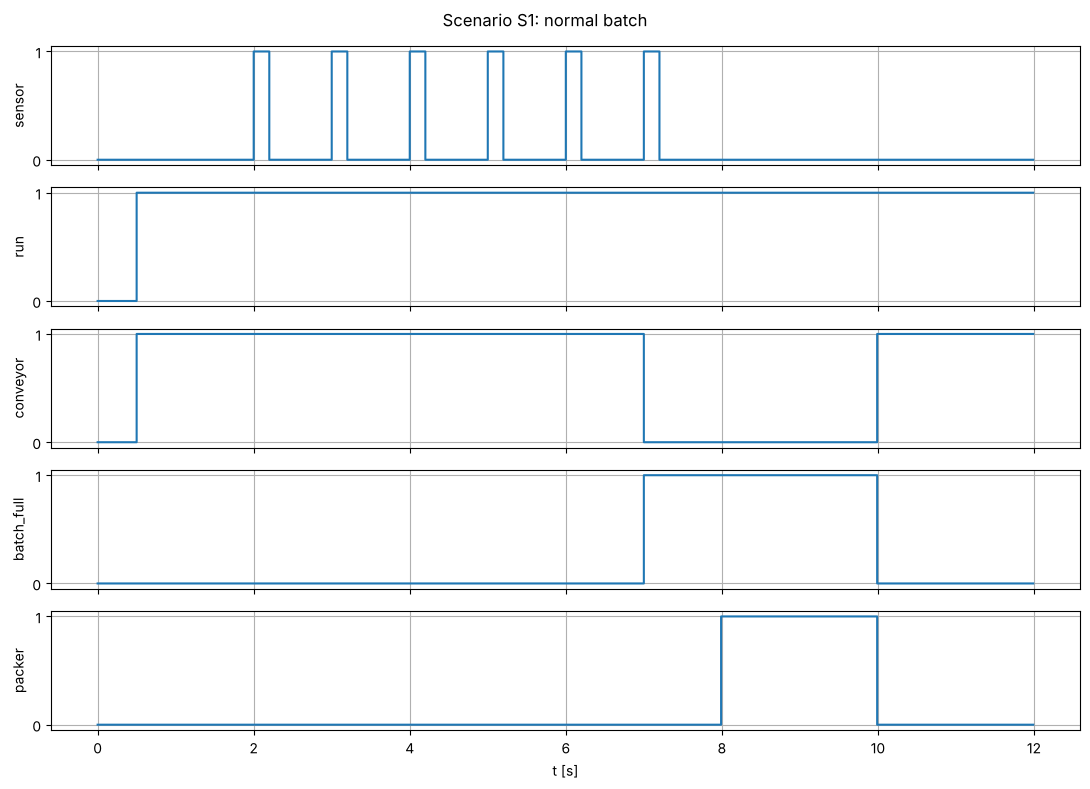

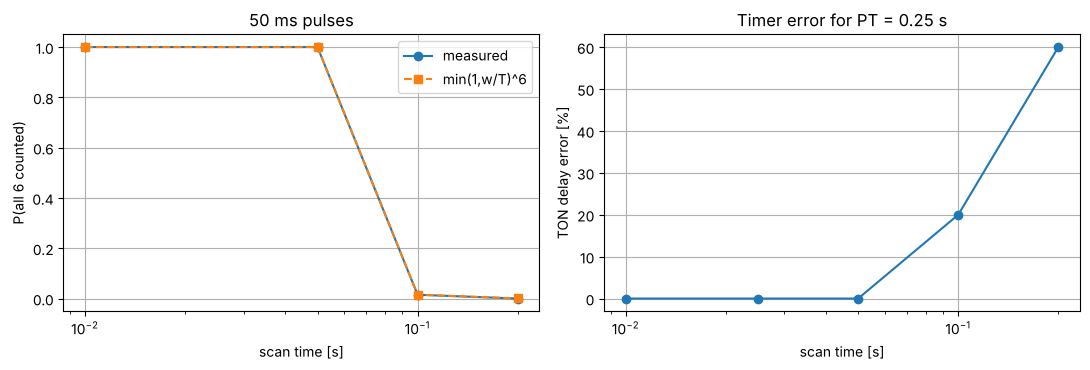

In [4]:
fig, ax = plt.subplots(5, 1, figsize=(11, 8), sharex=True)
t = np.array([r["t"] for r in s1])
for a, key in zip(ax, ["sensor", "run", "conveyor", "batch_full", "packer"]):
    y = [r["in"]["sensor"] if key == "sensor" else r["out"][key] for r in s1]
    a.step(t, np.array(y, dtype=int), where="post"); a.set(ylabel=key, yticks=[0, 1])
ax[-1].set_xlabel("t [s]"); fig.suptitle("Scenario S1: normal batch")
fig.tight_layout()
figs = [save_figure(fig, EXP, "scenario_normal_batch")]
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
Ts_ = list(mc); ax[0].plot(Ts_, [mc[T]["p_all_six_counted"] for T in Ts_], "o-", label="measured"); ax[0].plot(Ts_, [mc[T]["p_theory"] for T in Ts_], "s--", label="min(1,w/T)^6")
ax[0].set(xscale="log", xlabel="scan time [s]", ylabel="P(all 6 counted)", title="50 ms pulses"); ax[0].legend()
ax[1].plot(list(res), [res[d]["error_percent"] for d in res], "o-"); ax[1].set(xscale="log", xlabel="scan time [s]", ylabel="TON delay error [%]", title="Timer error for PT = 0.25 s")
fig.tight_layout()
figs.append(save_figure(fig, EXP, "scan_time_effects"))
plt.show()

The left plot shows that a pulse equal to the scan time is always seen but a pulse half as wide is
seen half the time; six in a row compounds to 1.6% at 100 ms scan. The right plot is the timer rounding
up to the next scan multiple.

## 14. Research Discussion and Limitations

**Facts from this run (scenario checks are in section 12).** In scenario S1 the conveyor stops in the same scan as the sixth
rising edge, the packer runs exactly 200 scans, and the counter resets one scan after the pack timer ends. With 50 ms
pulses, scan times of 10 ms and 50 ms count all six bottles in every trial; 100 ms and 200 ms
almost never do, matching `min(1, w/T)^6` within the stated tolerance.

**Inference.** For a pulse sensor, the scan time (or a hardware-interrupt/high-speed counter input)
must be set from the minimum pulse width, not from the sequence speed.

**Limits.** (1) This is an emulation of the scan model with one input image per scan. Real PLCs add input
filter time (typically milliseconds, set in hardware), output update delay and, for some CPUs, interrupt tasks and
multiple tasks with different periods. (2) The timer and counter behaviour was checked against hand-derived timing,
not against the standard text or against a real PLC. (3) Program-order dependence (section 8) means the same
logic written in a different network order gives different scan timing, and the expected values here are tied to the order used.
(4) No safety function: real emergency stop circuits are hard-wired and not implemented in standard PLC logic.
(5) Mechanical details (bottle spacing, conveyor inertia, sensor response) are not modelled.

## 15. Summary, Exercises, and Further Research

**Key insights.** Timers round up to the scan time and short pulses can be missed; derive expected
timelines in scan indices and compare them scan by scan.

**Exercises.** (1) Move the counter after the settle timer in the program and rerun S1: which indices change?
(2) Add a 20 ms input filter to the sensor and recompute the missed-pulse probability. (3) Add a
`TOF` that keeps a lamp on 3 s after pack done. (4) Replace the SR latch with a start-dominant latch and run S3.

**Related.** FSM (05), conveyor speed (11).
**Research directions.** Verification of PLC programs against timing properties and scan-time analysis.

In [5]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="PLC scan-cycle emulation: batching station",
    notebook="notebooks/03_discrete/07_plc_sequence.ipynb",
    algorithm="IEC 61131-3 style function blocks in a scan-cycle emulation",
    application="Bottle batching station (illustrative)", plant_model="Scripted discrete inputs; no plant dynamics",
    dataset={"name": "none", "kind": "simulated", "description": "Scripted sensor pulses and seeded random pulse phases."},
    metrics={"timer_resolution": {str(k): v for k, v in res.items()}, "missed_pulse": {str(k): v for k, v in mc.items()},
             "scenario_s1": {"conveyor_stop_scan": 700, "packer_scans": len(pk), "conveyor_restart_scan": 999}},
    checks=checks, sampling_time_s=DT, random_seed=SEED, number_of_trials=N_TR * len(mc),
    controller_parameters={"count_preset": 6, "settle_s": 1.0, "pack_s": 2.0, "latch": "reset dominant"},
    plant_parameters={}, input_configuration={"pulse_width_s": W}, disturbance_configuration={"estop_scan_range": [850, 900]},
    operating_conditions={"reference_scan_time_s": DT}, figure_references=figs,
    limitations=["Emulation of the scan model, not a PLC runtime and not compliance-tested.",
                 "Function-block behaviour verified against hand-derived timing, not the standard text.",
                 "No input filters, output delay, interrupts or multi-task scheduling.",
                 "No safety function; mechanical dynamics not modelled.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_07_plc_batching_station.json
